# Model Comparison: Which Model Should the App Use?

## 1. Introduction

This notebook asks which model the app should use and whether synthetic data helps. Every model is scored on the same untouched `diabetes_model_test` (14,039 rows). Thresholds for models trained here come only from five-fold out-of-fold (OOF) training predictions; the test set is never used to set an operating threshold.

### 1.1 The Models

- **M1:** Load `logreg_70k.joblib`, logistic regression trained on the 70k real-data training table.
- **M2:** Load `logreg_200k.joblib`, logistic regression trained on 200k real and synthetic rows.
- **M3:** Real-only control trained on the `is_synthetic = 0` rows of `diabetes_cmu_synth_train` (100,000 no + 28,078 yes), using M1's features and `class_weight="balanced"`.
- **M4:** Feature control trained on `diabetes_model_train` using M2's features.
- **M5:** Load `../06_multilinearreg/linprob_70k.joblib`; reference only, because a linear probability model is not the appropriate tool for this classification task.
- **M6:** Sensitivity model trained on M1's data and features, excluding only `CholCheck`, `AnyHealthcare`, and `NoDocbcCost` when present.

### 1.2 Decision Rule (set before reviewing results)

> Choose a model other than M1 only if, at 85% Recall on the test set, its precision (balanced test set) is at least 0.02 higher than M1's **and** the 95% paired-bootstrap interval of that difference excludes 0. Ties go to the simpler model trained only on real data.

ROC AUC is reported for context but does not decide the winner.

In [30]:
# Data and core analysis
import numpy as np
import pandas as pd

from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, brier_score_loss, confusion_matrix, f1_score,
    precision_recall_curve, roc_auc_score, roc_curve,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
from pathlib import Path

RANDOM_STATE = 42
TARGET_RECALL = 0.85
REAL_PREVALENCE = 0.14
N_BOOTSTRAP = 1000

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

engine = create_engine("mysql+pymysql://root:@localhost:3306/diabetes_final_db")
print("Libraries imported and connected successfully.")

Libraries imported and connected successfully.


## 2. Load Data and Models

We load the untouched test set and the two training sets (`diabetes_model_train` and `diabetes_cmu_synth_train`). We also load the two saved model bundles (M1 and M2). 

Because we are loading saved models, we check the `sklearn_version` in the bundle against the current environment. If they differ significantly, predictions can fail or change silently.

In [31]:
# Load the test set and training tables
test_df = pd.read_sql("SELECT * FROM diabetes_model_test", con=engine)
train_70k = pd.read_sql("SELECT * FROM diabetes_model_train", con=engine)
train_200k = pd.read_sql("SELECT * FROM diabetes_cmu_synth_train", con=engine)

# Load the saved reference bundles
bundle_70k = joblib.load("../../application/models/logreg_70k.joblib")
bundle_200k = joblib.load("../../application/models/logreg_200k.joblib")
bundle_linprob = joblib.load("../06_multilinearreg/linprob_70k.joblib")

import sklearn
print(f"Current sklearn version: {sklearn.__version__}")
print(f"M1 bundle version:       {bundle_70k.get('sklearn_version', 'unknown')}")
print(f"M2 bundle version:       {bundle_200k.get('sklearn_version', 'unknown')}")
print(f"M5 bundle version:       {bundle_linprob.get('sklearn_version', 'unknown')}")
if len(test_df) != 14_039:
    raise RuntimeError(f"Expected the untouched 14,039-row test set; found {len(test_df):,}.")
print(f"Test rows: {len(test_df):,}; M1 training rows: {len(train_70k):,}; M2 training rows: {len(train_200k):,}")

real_200k = train_200k.loc[train_200k["is_synthetic"] == 0].copy()
synthetic_rows = int((train_200k["is_synthetic"] == 1).sum())
real_positive_rows = int((real_200k["Diabetes_binary"] == 1).sum())
real_negative_rows = int((real_200k["Diabetes_binary"] == 0).sum())
assert (real_negative_rows, real_positive_rows) == (100_000, 28_078), (
    "The real-only M3 training rows do not match the required 100,000 no / 28,078 yes."
)

model_inventory = pd.DataFrame([
    {"Model": "M1", "Features": ", ".join(bundle_70k["features"]), "Threshold": bundle_70k["threshold"], "Training rows": len(train_70k), "Synthetic rows": 0},
    {"Model": "M2", "Features": ", ".join(bundle_200k["features"]), "Threshold": bundle_200k["threshold"], "Training rows": len(train_200k), "Synthetic rows": synthetic_rows},
    {"Model": "M3", "Features": ", ".join(bundle_70k["features"]), "Threshold": "5-fold OOF (Section 4)", "Training rows": len(real_200k), "Synthetic rows": 0},
    {"Model": "M4", "Features": ", ".join(bundle_200k["features"]), "Threshold": "5-fold OOF (Section 4)", "Training rows": len(train_70k), "Synthetic rows": 0},
    {"Model": "M5", "Features": ", ".join(bundle_linprob["features"]), "Threshold": bundle_linprob["threshold"], "Training rows": len(train_70k), "Synthetic rows": 0},
    {"Model": "M6", "Features": ", ".join([f for f in bundle_70k["features"] if f not in ["CholCheck", "AnyHealthcare", "NoDocbcCost"]]), "Threshold": "5-fold OOF (Section 4)", "Training rows": len(train_70k), "Synthetic rows": 0},
])
display(model_inventory.style.hide(axis="index").set_properties(**{"text-align": "left"}))
print("Data and saved bundles loaded successfully.")

Current sklearn version: 1.9.1
M1 bundle version:       1.9.1
M2 bundle version:       1.9.1
M5 bundle version:       1.9.1
Test rows: 14,039; M1 training rows: 56,155; M2 training rows: 200,000


Model,Features,Threshold,Training rows,Synthetic rows
M1,"HighBP, HighChol, BMI, Stroke, HeartDiseaseorAttack, PhysActivity, Fruits, HvyAlcoholConsump, GenHlth, MentHlth, PhysHlth, DiffWalk, Sex, Age, Education, Income",0.396179,56155,0
M2,"HighBP, HighChol, BMI, Stroke, HeartDiseaseorAttack, PhysActivity, Fruits, HvyAlcoholConsump, GenHlth, MentHlth, PhysHlth, DiffWalk, Sex, Age, Education, Income",0.376056,200000,71922
M3,"HighBP, HighChol, BMI, Stroke, HeartDiseaseorAttack, PhysActivity, Fruits, HvyAlcoholConsump, GenHlth, MentHlth, PhysHlth, DiffWalk, Sex, Age, Education, Income",5-fold OOF (Section 4),128078,0
M4,"HighBP, HighChol, BMI, Stroke, HeartDiseaseorAttack, PhysActivity, Fruits, HvyAlcoholConsump, GenHlth, MentHlth, PhysHlth, DiffWalk, Sex, Age, Education, Income",5-fold OOF (Section 4),56155,0
M5,"HighBP, HighChol, BMI, Stroke, HeartDiseaseorAttack, PhysActivity, Fruits, HvyAlcoholConsump, GenHlth, MentHlth, PhysHlth, DiffWalk, Sex, Age, Education, Income",0.424078,56155,0
M6,"HighBP, HighChol, BMI, Stroke, HeartDiseaseorAttack, PhysActivity, Fruits, HvyAlcoholConsump, GenHlth, MentHlth, PhysHlth, DiffWalk, Sex, Age, Education, Income",5-fold OOF (Section 4),56155,0


Data and saved bundles loaded successfully.


The M1 and M2 model bundles currently share 16 features and exclude `CholCheck`, `AnyHealthcare`, and `NoDocbcCost`; the inventory above reports the actual artifact contents, rather than inferring features from older experiments. Scikit-learn version equality is a compatibility check, not proof that predictions or training histories are identical.

The M3 count is checked explicitly against 100,000 real no-diabetes rows and 28,078 real diabetes rows. The 200k training set has 143,845 more rows than the 70k training table.

## 3. Sanity Check: Reproducing the Saved Results

Before fitting controls, verify M2 against the rounded reference values and compare M1 with `diabetes_eval_logreg_70k`. The M2 metrics must agree to the reported three-decimal precision, and the M1 metrics must agree with the historical table within 0.001. Any mismatch raises a clear error and stops the comparison; do not continue with incompatible artifacts.

In [32]:
def evaluate(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_true, pred),
        "Recall (sensitivity)": tp / (tp + fn),
        "Specificity": tn / (tn + fp),
        "Precision": tp / (tp + fp) if (tp + fp) else np.nan,
        "F1": f1_score(y_true, pred),
        "ROC AUC": roc_auc_score(y_true, proba),
        "Brier score": brier_score_loss(y_true, proba),
        "Missed diabetes cases (false negatives)": fn,
        "Healthy people flagged (false positives)": fp,
    }


evaluate_classifier = evaluate
proba_200k = bundle_200k["model"].predict_proba(test_df[bundle_200k["features"]])[:, 1]
thr_200k = float(bundle_200k["threshold"])
proba_70k = bundle_70k["model"].predict_proba(test_df[bundle_70k["features"]])[:, 1]
thr_70k = float(bundle_70k["threshold"])

m2_default = evaluate_classifier(test_df["Diabetes_binary"], proba_200k, 0.50)
m2_chosen = evaluate_classifier(test_df["Diabetes_binary"], proba_200k, thr_200k)
m1_default = evaluate_classifier(test_df["Diabetes_binary"], proba_70k, 0.50)
m1_chosen = evaluate_classifier(test_df["Diabetes_binary"], proba_70k, thr_70k)

sanity_check = pd.DataFrame([
    {"Model": "M2 (threshold 0.50)", **m2_default},
    {"Model": f"M2 (saved threshold {thr_200k:.3f})", **m2_chosen},
    {"Model": f"M1 (saved threshold {thr_70k:.3f})", **m1_chosen},
])
display(sanity_check.style.hide(axis="index").set_properties(**{"text-align": "left"}).format({
    "Threshold": "{:.4f}", "Accuracy": "{:.4f}", "Recall (sensitivity)": "{:.4f}",
    "Specificity": "{:.4f}", "Precision": "{:.4f}", "F1": "{:.4f}",
    "ROC AUC": "{:.4f}", "Brier score": "{:.4f}"
}))

# Compare both operating points with the stored M1 evaluation table.
m1_reference = pd.read_sql("SELECT * FROM diabetes_eval_logreg_70k", con=engine)
display(m1_reference)
m1_reference_by_threshold = m1_reference.set_index("Threshold")
m1_mismatch = {}
for label, actual in [
    ("Default (0.50)", m1_default),
    (f"Chosen ({thr_70k:.2f})", m1_chosen),
]:
    reference_row = m1_reference_by_threshold.loc[label]
    for metric in [
        "Accuracy", "Recall (sensitivity)", "Specificity", "Precision",
        "F1", "ROC AUC", "Brier score",
    ]:
        observed = float(actual[metric])
        expected = float(reference_row[metric])
        if not np.isclose(observed, expected, atol=0.001, rtol=0):
            m1_mismatch[f"{label} / {metric}"] = (observed, expected)

# Reference figures are rounded to three decimals; require agreement at that precision.
expected_m2 = {
    "threshold_050": (m2_default["Threshold"], 0.500),
    "recall_050": (m2_default["Recall (sensitivity)"], 0.727),
    "specificity_050": (m2_default["Specificity"], 0.722),
    "precision_050": (m2_default["Precision"], 0.724),
    "auc_050": (m2_default["ROC AUC"], 0.800),
    "threshold_saved": (thr_200k, 0.376),
    "recall_saved": (m2_chosen["Recall (sensitivity)"], 0.849),
    "specificity_saved": (m2_chosen["Specificity"], 0.600),
    "precision_saved": (m2_chosen["Precision"], 0.680),
    "brier_saved": (m2_chosen["Brier score"], 0.182),
}
m2_mismatch = {}
for name, (actual, expected) in expected_m2.items():
    tolerance = 0.00051 if name.startswith("threshold") else 0.00051
    if not np.isclose(actual, expected, atol=tolerance, rtol=0):
        m2_mismatch[name] = (float(actual), expected)

if m1_mismatch or m2_mismatch:
    raise RuntimeError(
        "Sanity check failed; stop before comparing models. "
        f"M1 reference mismatches: {m1_mismatch}; M2 reference mismatches: {m2_mismatch}"
    )
print("M1 and M2 sanity checks match their reference results.")

Model,Threshold,Accuracy,Recall (sensitivity),Specificity,Precision,F1,ROC AUC,Brier score,Missed diabetes cases (false negatives),Healthy people flagged (false positives)
M2 (threshold 0.50),0.5000,0.7245,0.7266,0.7224,0.7235,0.7250,0.7999,0.1824,1919,1949
M2 (saved threshold 0.376),0.3761,0.7246,0.8493,0.6000,0.6798,0.7551,0.7999,0.1824,1058,2808
M1 (saved threshold 0.396),0.3962,0.7257,0.8496,0.6019,0.6809,0.7559,0.8003,0.1817,1056,2795


,Model,Threshold,Accuracy,Recall (sensitivity),Specificity,Precision,F1,ROC AUC,Brier score,Missed diabetes cases (false negatives),Healthy people flagged (false positives)
0,Logistic regression (70k real rows),Default (0.50),0.727545,0.744978,0.710114,0.719851,0.732199,0.80033,0.1817,1790.0,2035.0
1,Logistic regression (70k real rows),Chosen (0.40),0.725693,0.849551,0.601852,0.680863,0.755911,0.80033,0.1817,1056.0,2795.0


M1 and M2 sanity checks match their reference results.


The comparison displays the loaded-bundle M1 and M2 metrics alongside the stored M1 evaluation table. Reference values rounded to three decimals must match within 0.00051; otherwise a `RuntimeError` stops the notebook before model fitting or test-set analysis. The historical 70k reference came from an all-21-feature model (ROC AUC 0.802 and recall 0.849 at threshold 0.40); the currently loaded M1 bundle has 16 features, so these artifacts must not be conflated.

## 4. Build the Remaining Models (M3, M4, M5, M6)

M3 uses the real-only rows of the 200k training table, M1's feature list, and `class_weight="balanced"`. Plain stratified folds are appropriate because M3 contains no synthetic rows. M4 uses M1's training table with M2's feature list. M5 is loaded only as a reference. M6 uses M1's training data and drops only the access features that are present.

M3, M4, and M6 use the same `make_logreg` pipeline pattern as the earlier training notebooks. Each threshold is derived from five-fold OOF training probabilities via `threshold_for`, never from the test set.

In [33]:
NON_BINARY = ["BMI", "GenHlth", "MentHlth", "PhysHlth", "Age", "Education", "Income"]
HEALTHCARE_FEATURES = ["CholCheck", "AnyHealthcare", "NoDocbcCost"]

def make_logreg(cols, class_weight=None):
    scale_cols = [col for col in cols if col in NON_BINARY]
    prep = ColumnTransformer(
        [("scale", StandardScaler(), scale_cols)],
        remainder="passthrough",
        verbose_feature_names_out=False,
    )
    return Pipeline([
        ("prep", prep),
        ("model", LogisticRegression(
            C=np.inf, max_iter=2000, class_weight=class_weight, random_state=RANDOM_STATE
        )),
    ])

def threshold_for(y_true, oof_proba, goal=TARGET_RECALL):
    precision, recall, thresholds = precision_recall_curve(y_true, oof_proba)
    eligible = thresholds[recall[:-1] >= goal]
    if eligible.size == 0:
        raise ValueError(f"No OOF threshold reaches the requested recall goal {goal:.3f}.")
    return float(eligible.max())

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# M3: real-only 200k-table rows, M1 features, balanced class weights
X_m3 = real_200k[bundle_70k["features"]]
y_m3 = real_200k["Diabetes_binary"]
m3_model = make_logreg(bundle_70k["features"], class_weight="balanced").fit(X_m3, y_m3)
oof_m3 = np.zeros(len(X_m3))
for tr_idx, va_idx in skf.split(X_m3, y_m3):
    fold_model = make_logreg(bundle_70k["features"], class_weight="balanced")
    fold_model.fit(X_m3.iloc[tr_idx], y_m3.iloc[tr_idx])
    oof_m3[va_idx] = fold_model.predict_proba(X_m3.iloc[va_idx])[:, 1]
thr_m3 = threshold_for(y_m3, oof_m3)
proba_m3 = m3_model.predict_proba(test_df[bundle_70k["features"]])[:, 1]

# M4: M1 training table with M2 features
X_m4 = train_70k[bundle_200k["features"]]
y_m4 = train_70k["Diabetes_binary"]
m4_model = make_logreg(bundle_200k["features"]).fit(X_m4, y_m4)
oof_m4 = np.zeros(len(X_m4))
for tr_idx, va_idx in skf.split(X_m4, y_m4):
    fold_model = make_logreg(bundle_200k["features"])
    fold_model.fit(X_m4.iloc[tr_idx], y_m4.iloc[tr_idx])
    oof_m4[va_idx] = fold_model.predict_proba(X_m4.iloc[va_idx])[:, 1]
thr_m4 = threshold_for(y_m4, oof_m4)
proba_m4 = m4_model.predict_proba(test_df[bundle_200k["features"]])[:, 1]

# M5: linear probability model, reference only
proba_m5 = np.clip(
    bundle_linprob["model"].predict(test_df[bundle_linprob["features"]]), 0, 1
)
thr_m5 = float(bundle_linprob["threshold"])

# M6: M1 data and features, excluding only access features present
m6_features = [col for col in bundle_70k["features"] if col not in HEALTHCARE_FEATURES]
X_m6 = train_70k[m6_features]
y_m6 = train_70k["Diabetes_binary"]
m6_model = make_logreg(m6_features).fit(X_m6, y_m6)
oof_m6 = np.zeros(len(X_m6))
for tr_idx, va_idx in skf.split(X_m6, y_m6):
    fold_model = make_logreg(m6_features)
    fold_model.fit(X_m6.iloc[tr_idx], y_m6.iloc[tr_idx])
    oof_m6[va_idx] = fold_model.predict_proba(X_m6.iloc[va_idx])[:, 1]
thr_m6 = threshold_for(y_m6, oof_m6)
proba_m6 = m6_model.predict_proba(test_df[m6_features])[:, 1]

thresholds_by_model = {
    "M1": thr_70k, "M2": thr_200k, "M3": thr_m3,
    "M4": thr_m4, "M5": thr_m5, "M6": thr_m6,
}
model_inventory["Threshold"] = model_inventory["Model"].map(thresholds_by_model)
display(model_inventory.style.hide(axis="index").set_properties(**{"text-align": "left"}).format({
    "Threshold": "{:.4f}", "Training rows": "{:,}", "Synthetic rows": "{:,}"
}))

print(f"M3 OOF threshold: {thr_m3:.4f}")
print(f"M4 OOF threshold: {thr_m4:.4f}")
print(f"M5 saved threshold: {thr_m5:.4f}")
print(f"M6 OOF threshold: {thr_m6:.4f}")

Model,Features,Threshold,Training rows,Synthetic rows
M1,"HighBP, HighChol, BMI, Stroke, HeartDiseaseorAttack, PhysActivity, Fruits, HvyAlcoholConsump, GenHlth, MentHlth, PhysHlth, DiffWalk, Sex, Age, Education, Income",0.3962,"56,155",0
M2,"HighBP, HighChol, BMI, Stroke, HeartDiseaseorAttack, PhysActivity, Fruits, HvyAlcoholConsump, GenHlth, MentHlth, PhysHlth, DiffWalk, Sex, Age, Education, Income",0.3761,"200,000","71,922"
M3,"HighBP, HighChol, BMI, Stroke, HeartDiseaseorAttack, PhysActivity, Fruits, HvyAlcoholConsump, GenHlth, MentHlth, PhysHlth, DiffWalk, Sex, Age, Education, Income",0.3971,"128,078",0
M4,"HighBP, HighChol, BMI, Stroke, HeartDiseaseorAttack, PhysActivity, Fruits, HvyAlcoholConsump, GenHlth, MentHlth, PhysHlth, DiffWalk, Sex, Age, Education, Income",0.3962,"56,155",0
M5,"HighBP, HighChol, BMI, Stroke, HeartDiseaseorAttack, PhysActivity, Fruits, HvyAlcoholConsump, GenHlth, MentHlth, PhysHlth, DiffWalk, Sex, Age, Education, Income",0.4241,"56,155",0
M6,"HighBP, HighChol, BMI, Stroke, HeartDiseaseorAttack, PhysActivity, Fruits, HvyAlcoholConsump, GenHlth, MentHlth, PhysHlth, DiffWalk, Sex, Age, Education, Income",0.3962,"56,155",0


M3 OOF threshold: 0.3971
M4 OOF threshold: 0.3962
M5 saved threshold: 0.4241
M6 OOF threshold: 0.3962


The trained-control thresholds are learned from five-fold OOF predictions on each model's own training rows. M3 alone uses balanced class weights, as specified; M4 and M6 preserve M1's unweighted logistic-regression setup. The M5 threshold is loaded from its reference bundle.

## 5. Test Results at Own Threshold and Default

We now score all six models on the untouched 14,039 test rows. We report the metrics at two points:

- **At their own threshold:** The threshold each model chose during training to hit the 85% recall goal. This shows the practical operating point for the app.
- **At the default 0.50 threshold:** This provides a standard reference point across models, showing how they behave without a custom threshold.

We also report precision and the share of the population flagged at the real-world prevalence of 14%. This is crucial because the balanced test set (50/50) makes precision look artificially high. At 14% prevalence, we see the true burden of false positives.

In [34]:
# Ensure the helper function is available (from Cell 6)
def at_real_prevalence(recall, specificity, prevalence=REAL_PREVALENCE):
    flagged = recall * prevalence + (1 - specificity) * (1 - prevalence)
    return recall * prevalence / flagged if flagged > 0 else np.nan, flagged

# Dictionary of all models, their probabilities, and their thresholds
models = {
    "M1: 70k (real)":            (proba_70k,  thr_70k),
    "M2: 200k (real + synth)":   (proba_200k, thr_200k),
    "M3: 128k (real only)":      (proba_m3,   thr_m3),
    "M4: 70k (200k features)":   (proba_m4,   thr_m4),
    "M5: Linear Prob":           (proba_m5,   thr_m5),
    "M6: 70k (no access)":       (proba_m6,   thr_m6),
}

rows = []
for name, (proba, thr) in models.items():
    for label, threshold in [("Own threshold", thr), ("Default (0.50)", 0.50)]:
        m = evaluate_classifier(test_df["Diabetes_binary"].values, proba, threshold)
        prec_real, flagged_real = at_real_prevalence(m["Recall (sensitivity)"], m["Specificity"])
        m["Model"] = name
        m["Point"] = label
        m["Precision @ 14%"] = prec_real
        m["Share flagged @ 14%"] = flagged_real
        rows.append(m)

results_df = pd.DataFrame(rows)[[
    "Model", "Point", "Threshold", "Accuracy", "Recall (sensitivity)", "Specificity",
    "Precision", "F1", "ROC AUC", "Brier score",
    "Precision @ 14%", "Share flagged @ 14%"
]]

display(
    results_df.style.hide(axis="index").set_properties(**{"text-align": "left"})
               .format({
                   "Threshold": "{:.3f}", "Accuracy": "{:.4f}",
                   "Recall (sensitivity)": "{:.4f}", "Specificity": "{:.4f}",
                   "Precision": "{:.4f}", "F1": "{:.4f}", "ROC AUC": "{:.4f}",
                   "Brier score": "{:.4f}", "Precision @ 14%": "{:.4f}",
                   "Share flagged @ 14%": "{:.4f}"
               })
)

Model,Point,Threshold,Accuracy,Recall (sensitivity),Specificity,Precision,F1,ROC AUC,Brier score,Precision @ 14%,Share flagged @ 14%
M1: 70k (real),Own threshold,0.396,0.7257,0.8496,0.6019,0.6809,0.7559,0.8003,0.1817,0.2578,0.4613
M1: 70k (real),Default (0.50),0.500,0.7275,0.7450,0.7101,0.7199,0.7322,0.8003,0.1817,0.2950,0.3536
M2: 200k (real + synth),Own threshold,0.376,0.7246,0.8493,0.6000,0.6798,0.7551,0.7999,0.1824,0.2569,0.4629
M2: 200k (real + synth),Default (0.50),0.500,0.7245,0.7266,0.7224,0.7235,0.7250,0.7999,0.1824,0.2988,0.3405
M3: 128k (real only),Own threshold,0.397,0.7260,0.8476,0.6044,0.6818,0.7557,0.8004,0.1817,0.2586,0.4589
M3: 128k (real only),Default (0.50),0.500,0.7277,0.7460,0.7094,0.7196,0.7326,0.8004,0.1817,0.2947,0.3544
M4: 70k (200k features),Own threshold,0.396,0.7257,0.8496,0.6019,0.6809,0.7559,0.8003,0.1817,0.2578,0.4613
M4: 70k (200k features),Default (0.50),0.500,0.7275,0.7450,0.7101,0.7199,0.7322,0.8003,0.1817,0.2950,0.3536
M5: Linear Prob,Own threshold,0.424,0.7250,0.8504,0.5996,0.6798,0.7556,0.7994,0.1831,0.2569,0.4634
M5: Linear Prob,Default (0.50),0.500,0.7265,0.7527,0.7003,0.7152,0.7334,0.7994,0.1831,0.2902,0.3631


Use the results table as the source for point estimates. The app-facing precision at 14% prevalence is distinct from precision on this balanced test set; they answer different questions. Do not infer that a small AUC difference establishes a meaningful clinical improvement.

## 6. Matched-Recall Comparison (Descriptive)

For each model, this section reads the threshold nearest 85% recall from the **test-set curve solely for descriptive comparison**. That test-derived threshold is never used to select a deployed threshold. The table reports balanced-test precision and specificity, plus precision and share flagged at 14% prevalence.

In [35]:
matched_rows = []
y_test = test_df["Diabetes_binary"].to_numpy()
for name, (proba, _) in models.items():
    precision_curve, recall_curve, thresholds = precision_recall_curve(y_test, proba)
    idx = int(np.argmin(np.abs(recall_curve[:-1] - TARGET_RECALL)))
    matched_thr = float(thresholds[idx])
    metrics = evaluate_classifier(y_test, proba, matched_thr)
    precision_real, flagged_real = at_real_prevalence(
        metrics["Recall (sensitivity)"], metrics["Specificity"]
    )
    matched_rows.append({
        "Model": name,
        "Threshold (test; descriptive only)": matched_thr,
        "Recall": metrics["Recall (sensitivity)"],
        "Specificity": metrics["Specificity"],
        "Precision (balanced)": metrics["Precision"],
        "Precision @ 14%": precision_real,
        "Share flagged @ 14%": flagged_real,
    })

matched_df = pd.DataFrame(matched_rows)
display(matched_df.style.hide(axis="index").set_properties(**{"text-align": "left"}).format({
    "Threshold (test; descriptive only)": "{:.4f}", "Recall": "{:.4f}",
    "Specificity": "{:.4f}", "Precision (balanced)": "{:.4f}",
    "Precision @ 14%": "{:.4f}", "Share flagged @ 14%": "{:.4f}"
}))

Model,Threshold (test; descriptive only),Recall,Specificity,Precision (balanced),Precision @ 14%,Share flagged @ 14%
M1: 70k (real),0.3956,0.8500,0.6014,0.6807,0.2577,0.4618
M2: 200k (real + synth),0.3749,0.8500,0.5983,0.6790,0.2562,0.4645
M3: 128k (real only),0.3945,0.8500,0.6006,0.6803,0.2573,0.4625
M4: 70k (200k features),0.3956,0.8500,0.6014,0.6807,0.2577,0.4618
M5: Linear Prob,0.4243,0.8500,0.5996,0.6797,0.2568,0.4634
M6: 70k (no access),0.3956,0.8500,0.6014,0.6807,0.2577,0.4618


The test-derived matched thresholds are descriptive only. Use the paired-bootstrap precision-difference interval in Section 8, not this single test-set point estimate alone, when applying the pre-registered decision rule.

## 7. ROC and Calibration Curves

ROC curves and AUCs are shown for context; ROC AUC does not decide the model choice. Calibration curves and Brier scores are on the balanced test-data probability scale, not the 14% population-prevalence scale. The test set remains the same untouched set for every model.

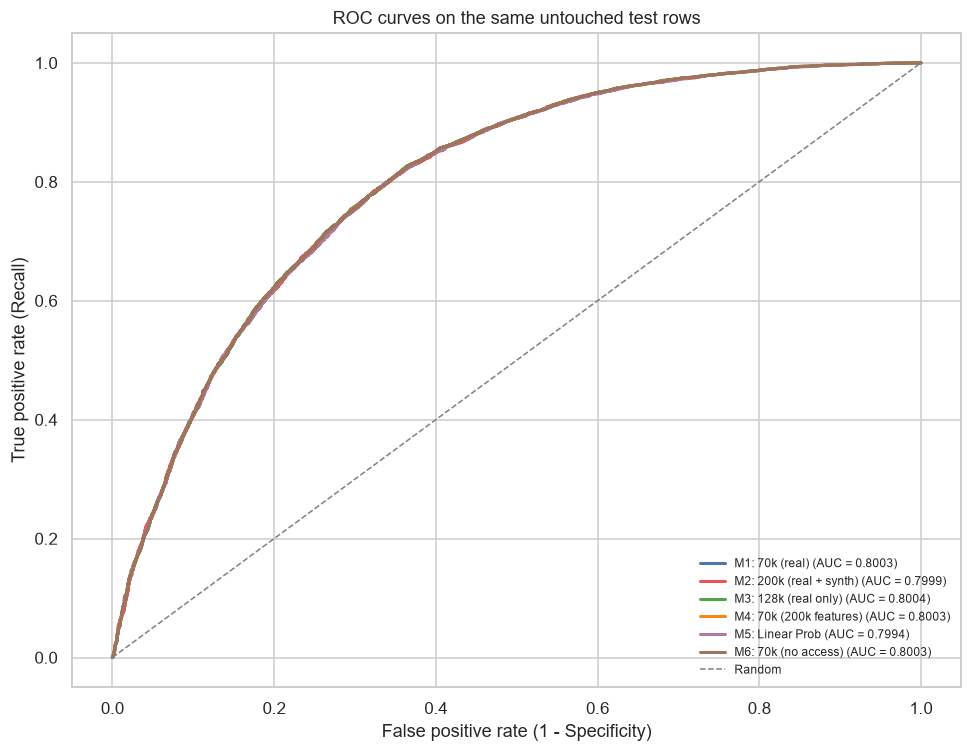

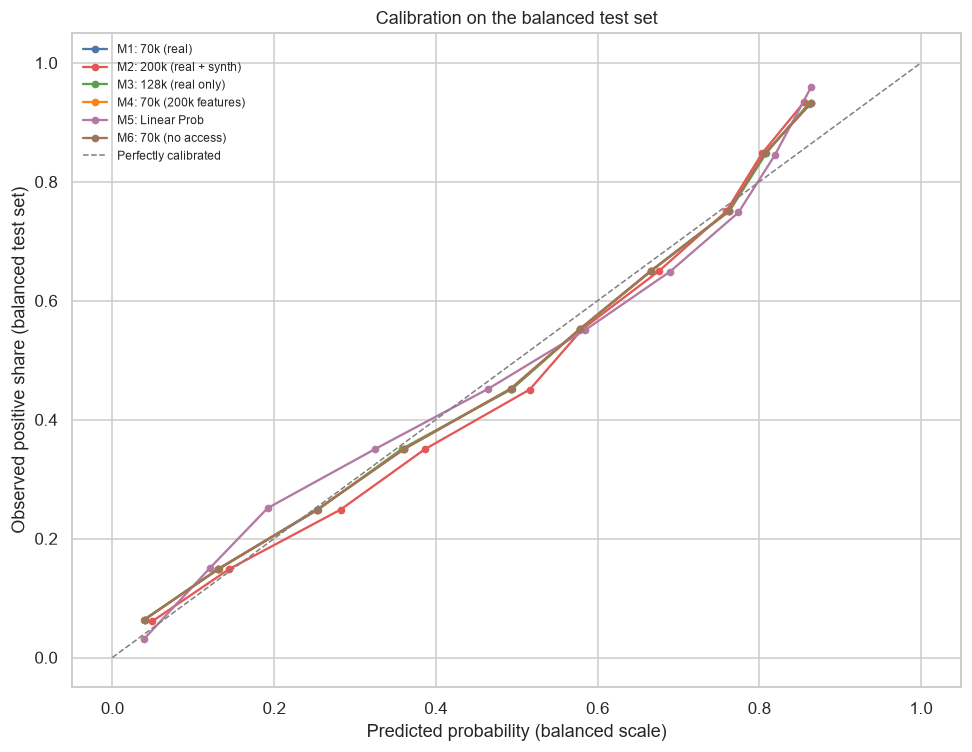

ROC curves, AUCs, calibration curves, and Brier scores are shown above.


In [36]:
# ROC curves for all models
fig, ax = plt.subplots(figsize=(9, 7))
colors = ["#4C78A8", "#E45756", "#54A24B", "#F58518", "#B279A2", "#9D755D"]
for (name, (proba, _)), color in zip(models.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})", color=color, lw=2)
ax.plot([0, 1], [0, 1], "--", color="grey", lw=1, label="Random")
ax.set_xlabel("False positive rate (1 - Specificity)")
ax.set_ylabel("True positive rate (Recall)")
ax.set_title("ROC curves on the same untouched test rows")
ax.legend(loc="lower right", frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

# Calibration curves on the balanced test scale
fig, ax = plt.subplots(figsize=(9, 7))
for (name, (proba, _)), color in zip(models.items(), colors):
    mean_pred, frac_pos = calibration_curve(
        y_test, proba, n_bins=10, strategy="uniform"
    )
    ax.plot(mean_pred, frac_pos, "o-", label=name, color=color, lw=1.5, markersize=4)
ax.plot([0, 1], [0, 1], "--", color="grey", lw=1, label="Perfectly calibrated")
ax.set_xlabel("Predicted probability (balanced scale)")
ax.set_ylabel("Observed positive share (balanced test set)")
ax.set_title("Calibration on the balanced test set")
ax.legend(loc="upper left", frameon=False, fontsize=8)
plt.tight_layout()
plt.show()
print("ROC curves, AUCs, calibration curves, and Brier scores are shown above.")

Read curves descriptively. Their apparent overlap does not prove clinical equivalence; uncertainty and the decision rule are assessed separately below. The calibration plot is based on a balanced test set, so it must not be described as calibration to the 14% population prevalence.

## 8. Uncertainty: Paired Bootstrap

Use 1,000 paired bootstrap resamples of the 14,039 test rows with seed 42. Each replicate uses the same sampled row indices for every model. Report 95% percentile intervals for each model's ROC AUC, recall and specificity at its locked training threshold, and precision at matched 85% recall. Also report the paired differences from M1 for all four metrics. For matched-recall precision, recompute the threshold inside every resample.

In [37]:
model_names = list(models)
model_probas = [models[name][0] for name in model_names]
model_thrs = [models[name][1] for name in model_names]
n_test = len(y_test)
n_models = len(model_names)

boot_auc = np.full((N_BOOTSTRAP, n_models), np.nan)
boot_recall = np.full((N_BOOTSTRAP, n_models), np.nan)
boot_specificity = np.full((N_BOOTSTRAP, n_models), np.nan)
boot_matched_precision = np.full((N_BOOTSTRAP, n_models), np.nan)

rng = np.random.default_rng(RANDOM_STATE)
for i in range(N_BOOTSTRAP):
    idx = rng.choice(n_test, size=n_test, replace=True)
    y_boot = y_test[idx]
    for j, (proba, chosen_threshold) in enumerate(zip(model_probas, model_thrs)):
        p_boot = proba[idx]
        boot_auc[i, j] = roc_auc_score(y_boot, p_boot)

        chosen_pred = (p_boot >= chosen_threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_boot, chosen_pred, labels=[0, 1]).ravel()
        boot_recall[i, j] = tp / (tp + fn) if tp + fn else np.nan
        boot_specificity[i, j] = tn / (tn + fp) if tn + fp else np.nan

        # Re-estimate the descriptive matched-recall threshold in this resample.
        _, recall_curve, matched_thresholds = precision_recall_curve(y_boot, p_boot)
        matched_idx = int(np.argmin(np.abs(recall_curve[:-1] - TARGET_RECALL)))
        matched_pred = (p_boot >= matched_thresholds[matched_idx]).astype(int)
        tn_m, fp_m, fn_m, tp_m = confusion_matrix(
            y_boot, matched_pred, labels=[0, 1]
        ).ravel()
        boot_matched_precision[i, j] = (
            tp_m / (tp_m + fp_m) if tp_m + fp_m else np.nan
        )

bootstrap_metrics = {
    "ROC AUC": boot_auc,
    "Recall @ chosen threshold": boot_recall,
    "Specificity @ chosen threshold": boot_specificity,
    "Precision @ matched 85% Recall": boot_matched_precision,
}

ci_rows = []
for metric_name, samples in bootstrap_metrics.items():
    metric_ci = np.nanpercentile(samples, [2.5, 97.5], axis=0)
    differences = samples - samples[:, [0]]
    difference_ci = np.nanpercentile(differences, [2.5, 97.5], axis=0)
    point_estimates = {
        "ROC AUC": [roc_auc_score(y_test, p) for p in model_probas],
        "Recall @ chosen threshold": [
            evaluate_classifier(y_test, p, t)["Recall (sensitivity)"]
            for p, t in zip(model_probas, model_thrs)
        ],
        "Specificity @ chosen threshold": [
            evaluate_classifier(y_test, p, t)["Specificity"]
            for p, t in zip(model_probas, model_thrs)
        ],
        "Precision @ matched 85% Recall": matched_df.set_index("Model").loc[
            model_names, "Precision (balanced)"
        ].tolist(),
    }[metric_name]
    for j, name in enumerate(model_names):
        ci_rows.append({
            "Metric": metric_name,
            "Model": name,
            "Estimate": point_estimates[j],
            "Model 95% CI": f"[{metric_ci[0, j]:.4f}, {metric_ci[1, j]:.4f}]",
            "Difference vs M1": 0.0 if j == 0 else point_estimates[j] - point_estimates[0],
            "Difference vs M1 95% CI": (
                "[0.0000, 0.0000]" if j == 0
                else f"[{difference_ci[0, j]:+.4f}, {difference_ci[1, j]:+.4f}]"
            ),
        })

ci_df = pd.DataFrame(ci_rows)
display(ci_df.style.hide(axis="index").set_properties(**{"text-align": "left"}).format({
    "Estimate": "{:.4f}", "Difference vs M1": "{:+.4f}"
}))
print(f"Paired bootstrap complete: {N_BOOTSTRAP} resamples; seed={RANDOM_STATE}.")

Metric,Model,Estimate,Model 95% CI,Difference vs M1,Difference vs M1 95% CI
ROC AUC,M1: 70k (real),0.8003,"[0.7930, 0.8080]",+0.0000,"[0.0000, 0.0000]"
ROC AUC,M2: 200k (real + synth),0.7999,"[0.7925, 0.8074]",-0.0004,"[-0.0011, +0.0002]"
ROC AUC,M3: 128k (real only),0.8004,"[0.7930, 0.8080]",+0.0000,"[-0.0001, +0.0002]"
ROC AUC,M4: 70k (200k features),0.8003,"[0.7930, 0.8080]",+0.0000,"[+0.0000, +0.0000]"
ROC AUC,M5: Linear Prob,0.7994,"[0.7920, 0.8070]",-0.0009,"[-0.0014, -0.0004]"
ROC AUC,M6: 70k (no access),0.8003,"[0.7930, 0.8080]",+0.0000,"[+0.0000, +0.0000]"
Recall @ chosen threshold,M1: 70k (real),0.8496,"[0.8408, 0.8581]",+0.0000,"[0.0000, 0.0000]"
Recall @ chosen threshold,M2: 200k (real + synth),0.8493,"[0.8408, 0.8573]",-0.0003,"[-0.0034, +0.0028]"
Recall @ chosen threshold,M3: 128k (real only),0.8476,"[0.8388, 0.8559]",-0.0020,"[-0.0034, -0.0006]"
Recall @ chosen threshold,M4: 70k (200k features),0.8496,"[0.8408, 0.8581]",+0.0000,"[+0.0000, +0.0000]"


Paired bootstrap complete: 1000 resamples; seed=42.


The paired intervals account for resampling variation on this one holdout set. The precision interval used by the decision rule is for balanced-test precision at matched recall, and its threshold is re-estimated within every bootstrap replicate. The bootstrap does not establish causality or generalize beyond the sampled population.

## 9. Does Synthetic Data Help? (Data and Feature Attribution)

The comparison separates:

- **M1 vs M4:** feature-list effect, holding the 70k training table fixed.
- **M4 vs M2:** training-data effect under M2's feature list.
- **M2 vs M3:** synthetic-row effect, comparing the loaded 200k bundle with the real-only M3 control.
- **M1 vs M3:** additional-real-data comparison.

The 200k training set has 143,845 more rows than the 70k training set; do not describe this as “the extra 100,000 rows.”

Synthetic-data context: the generator is SMOTE-style. A random forest distinguishing real from synthetic diabetes rows had ROC AUC 0.650. Average responses shifted for `MentHlth` (4.50 real vs 5.30 synthetic) and `HvyAlcoholConsump` (0.023 real vs 0.017 synthetic).

The forest plot shows odds ratios per standard deviation for non-binary features and per 0-to-1 change for binary features. `CholCheck` and `AnyHealthcare` are highlighted when present. The currently loaded M1/M2 feature lists omit both, so their odds ratios cannot be estimated from these bundles.

Model,Feature count,Training rows,Synthetic rows,Recall @ own threshold,Specificity @ own threshold,Balanced precision @ own threshold,ROC AUC
M1,16,56155,0,0.8496,0.6019,0.6809,0.8003
M4,16,56155,0,0.8496,0.6019,0.6809,0.8003
M2,16,200000,71922,0.8493,0.6000,0.6798,0.7999
M3,16,128078,0,0.8476,0.6044,0.6818,0.8004


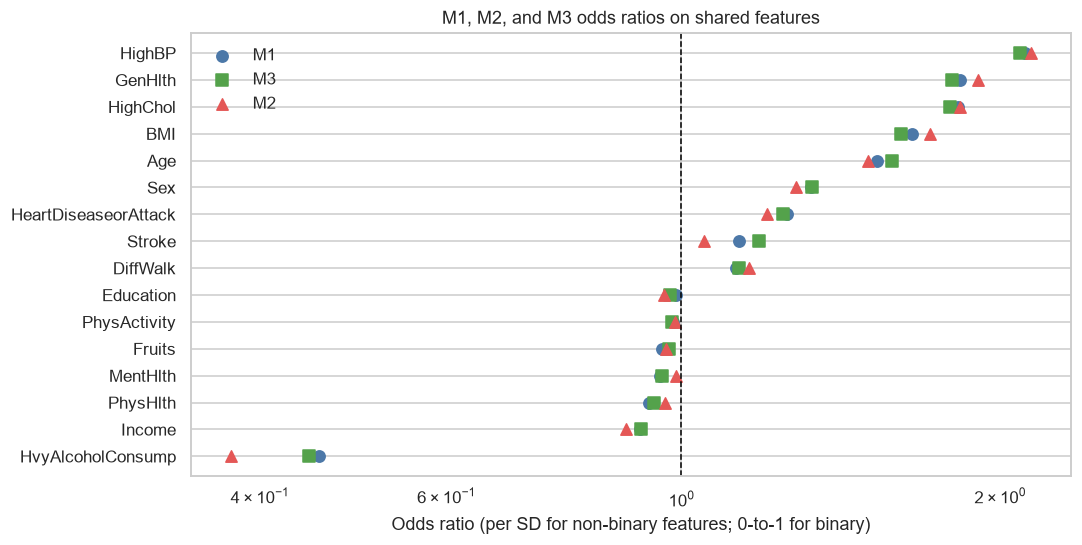

Not in the current shared feature list and therefore not estimable: ['AnyHealthcare', 'CholCheck']
M1 vs M4 isolates features; M4 vs M2 changes training data; M2 vs M3 isolates synthetic rows.


In [38]:
# Attribute data volume and feature-list effects using the same test rows
model_rows = []
for name, proba, threshold, features, train_rows, synthetic_count in [
    ("M1", proba_70k, thr_70k, bundle_70k["features"], len(train_70k), 0),
    ("M4", proba_m4, thr_m4, bundle_200k["features"], len(train_70k), 0),
    ("M2", proba_200k, thr_200k, bundle_200k["features"], len(train_200k), synthetic_rows),
    ("M3", proba_m3, thr_m3, bundle_70k["features"], len(real_200k), 0),
]:
    metrics = evaluate_classifier(y_test, proba, threshold)
    model_rows.append({
        "Model": name,
        "Feature count": len(features),
        "Training rows": train_rows,
        "Synthetic rows": synthetic_count,
        "Recall @ own threshold": metrics["Recall (sensitivity)"],
        "Specificity @ own threshold": metrics["Specificity"],
        "Balanced precision @ own threshold": metrics["Precision"],
        "ROC AUC": metrics["ROC AUC"],
    })
data_df = pd.DataFrame(model_rows)
display(data_df.style.hide(axis="index").set_properties(**{"text-align": "left"}).format({
    "Recall @ own threshold": "{:.4f}", "Specificity @ own threshold": "{:.4f}",
    "Balanced precision @ own threshold": "{:.4f}", "ROC AUC": "{:.4f}"
}))

def odds_ratios_in_pipeline(model, features):
    transformed_names = model.named_steps["prep"].get_feature_names_out()
    coefficients = pd.Series(model.named_steps["model"].coef_[0], index=transformed_names)
    return np.exp(coefficients.reindex(features))

shared_features = [
    feature for feature in bundle_70k["features"]
    if feature in bundle_200k["features"]
]
odds = pd.DataFrame({
    "M1": odds_ratios_in_pipeline(bundle_70k["model"], shared_features),
    "M2": odds_ratios_in_pipeline(bundle_200k["model"], shared_features),
    "M3": odds_ratios_in_pipeline(m3_model, shared_features),
})
odds = odds.sort_values("M1")

fig, ax = plt.subplots(figsize=(10, max(5, 0.32 * len(odds))))
y_pos = np.arange(len(odds))
for column, color, marker in [
    ("M1", "#4C78A8", "o"), ("M3", "#54A24B", "s"), ("M2", "#E45756", "^")
]:
    ax.scatter(odds[column], y_pos, color=color, label=column, marker=marker, s=55)
highlighted = {"CholCheck", "AnyHealthcare"}
ax.set_yticks(y_pos)
ax.set_yticklabels([
    f"{feature} *" if feature in highlighted else feature for feature in odds.index
])
ax.axvline(1.0, color="black", ls="--", lw=1)
ax.set_xscale("log")
ax.set_xlabel("Odds ratio (per SD for non-binary features; 0-to-1 for binary)")
ax.set_title("M1, M2, and M3 odds ratios on shared features")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()
missing_access = sorted(highlighted - set(shared_features))
if missing_access:
    print(f"Not in the current shared feature list and therefore not estimable: {missing_access}")
print("M1 vs M4 isolates features; M4 vs M2 changes training data; M2 vs M3 isolates synthetic rows.")

Interpret the attribution table as controlled contrasts, not proof that one factor caused a change. The currently loaded bundles share the same 16 features, so the feature contrast is expected to be informative only if M4's training/evaluation is verified. Synthetic realism and shifted averages are separate concerns from measured predictive performance. Healthcare-access odds ratios are not shown when those variables are absent from the current artifacts.

## 10. Healthcare-Access Check (Known Diagnosis-Access Concern)

Healthcare access can reflect who has been checked and diagnosed, not who is biologically at risk. The requested historical reference reports a CholCheck odds ratio of 4.69 in an earlier 200k model (about 3.3 in an earlier 70k model) and a high-blood-pressure example whose score changes from about 0.55 to 0.21 when CholCheck changes from 1 to 0.

Those historical values are **not outputs of the bundles loaded here**: the current M1/M2 artifacts contain 16 features and omit `CholCheck`, `AnyHealthcare`, and `NoDocbcCost`. The tables below report what the current six models actually support. A fixed-profile comparison changes CholCheck only, keeping other answers fixed. If a model does not use CholCheck, its two scores should be identical.

A screening tool should not treat lack of access or lack of a prior test as evidence of low risk. It should avoid access proxies where possible and provide a path to confirmatory screening and care, particularly for people facing barriers.

In [39]:
# Test-set access strata for every model, at its locked training threshold
test_access = test_df["CholCheck"].to_numpy()
access_rows = []
for name, (proba, threshold) in models.items():
    pred = (proba >= threshold).astype(int)
    for value, label in [(0, "CholCheck = 0"), (1, "CholCheck = 1")]:
        mask = test_access == value
        y_group = y_test[mask]
        pred_group = pred[mask]
        positives = int(y_group.sum())
        access_rows.append({
            "Model": name,
            "CholCheck group": label,
            "N": int(mask.sum()),
            "Recall": (
                float(((pred_group == 1) & (y_group == 1)).sum() / positives)
                if positives else np.nan
            ),
            "Share flagged": float(pred_group.mean()) if mask.any() else np.nan,
        })
access_df = pd.DataFrame(access_rows)
display(access_df.style.hide(axis="index").set_properties(**{"text-align": "left"}).format({
    "Recall": "{:.4f}", "Share flagged": "{:.4f}"
}))

# M6 cost relative to M1 on the same test set
m1_metrics = evaluate_classifier(y_test, proba_70k, thr_70k)
m6_metrics = evaluate_classifier(y_test, proba_m6, thr_m6)
access_cost_df = pd.DataFrame([{
    "M6 minus M1 ROC AUC": m6_metrics["ROC AUC"] - m1_metrics["ROC AUC"],
    "M6 minus M1 Recall": m6_metrics["Recall (sensitivity)"] - m1_metrics["Recall (sensitivity)"],
}])
display(access_cost_df.style.hide(axis="index").format({
    "M6 minus M1 ROC AUC": "{:+.4f}", "M6 minus M1 Recall": "{:+.4f}"
}))

# Fixed high-risk example; only CholCheck changes between rows.
profile_values = {
    "HighBP": 1, "HighChol": 1, "BMI": 35, "Stroke": 0,
    "HeartDiseaseorAttack": 0, "PhysActivity": 0, "Fruits": 0,
    "Veggies": 1, "HvyAlcoholConsump": 0, "GenHlth": 4,
    "MentHlth": 0, "PhysHlth": 0, "DiffWalk": 0, "Sex": 1,
    "Age": 10, "Education": 4, "Income": 5, "CholCheck": 1,
    "AnyHealthcare": 1, "NoDocbcCost": 0,
}
estimators = {
    "M1: 70k (real)": (bundle_70k["model"], bundle_70k["features"]),
    "M2: 200k (real + synth)": (bundle_200k["model"], bundle_200k["features"]),
    "M3: 128k (real only)": (m3_model, bundle_70k["features"]),
    "M4: 70k (200k features)": (m4_model, bundle_200k["features"]),
    "M5: Linear Prob": (bundle_linprob["model"], bundle_linprob["features"]),
    "M6: 70k (no access)": (m6_model, m6_features),
}
whatif_rows = []
for name, (estimator, features) in estimators.items():
    profile = pd.DataFrame([{feature: profile_values[feature] for feature in features}])
    profile_no_cholcheck = profile.copy()
    if "CholCheck" in profile_no_cholcheck:
        profile_no_cholcheck["CholCheck"] = 0
    if hasattr(estimator, "predict_proba"):
        score_yes = float(estimator.predict_proba(profile)[0, 1])
        score_no = float(estimator.predict_proba(profile_no_cholcheck)[0, 1])
    else:
        score_yes = float(np.clip(estimator.predict(profile)[0], 0, 1))
        score_no = float(np.clip(estimator.predict(profile_no_cholcheck)[0], 0, 1))
    whatif_rows.append({
        "Model": name,
        "Uses CholCheck": "CholCheck" in features,
        "Score with CholCheck=1": score_yes,
        "Score with CholCheck=0": score_no,
        "Score difference (0 - 1)": score_no - score_yes,
    })
whatif_df = pd.DataFrame(whatif_rows)
display(whatif_df.style.hide(axis="index").set_properties(**{"text-align": "left"}).format({
    "Score with CholCheck=1": "{:.4f}", "Score with CholCheck=0": "{:.4f}",
    "Score difference (0 - 1)": "{:+.4f}"
}))

Model,CholCheck group,N,Recall,Share flagged
M1: 70k (real),CholCheck = 0,356,0.9167,0.2612
M1: 70k (real),CholCheck = 1,13683,0.8492,0.6333
M2: 200k (real + synth),CholCheck = 0,356,0.9444,0.2753
M2: 200k (real + synth),CholCheck = 1,13683,0.8488,0.6337
M3: 128k (real only),CholCheck = 0,356,0.8889,0.2584
M3: 128k (real only),CholCheck = 1,13683,0.8473,0.6310
M4: 70k (200k features),CholCheck = 0,356,0.9167,0.2612
M4: 70k (200k features),CholCheck = 1,13683,0.8492,0.6333
M5: Linear Prob,CholCheck = 0,356,0.9167,0.2640
M5: Linear Prob,CholCheck = 1,13683,0.8501,0.6348


M6 minus M1 ROC AUC,M6 minus M1 Recall
+0.0000,+0.0000


Model,Uses CholCheck,Score with CholCheck=1,Score with CholCheck=0,Score difference (0 - 1)
M1: 70k (real),False,0.8789,0.8789,+0.0000
M2: 200k (real + synth),False,0.8777,0.8777,+0.0000
M3: 128k (real only),False,0.8771,0.8771,+0.0000
M4: 70k (200k features),False,0.8789,0.8789,+0.0000
M5: Linear Prob,False,0.8691,0.8691,+0.0000
M6: 70k (no access),False,0.8789,0.8789,+0.0000


The subgroup table reports each model's test-set group size, recall, and share flagged for CholCheck=0 and CholCheck=1. The M6 cost is the difference in ROC AUC and recall from M1 at their locked thresholds.

The what-if values are scores on the balanced scale. A zero difference is expected for current bundles that do not include CholCheck; it does not invalidate the separate historical concern about earlier full-feature models. Do not claim the historical 4.69 odds ratio or 0.55-to-0.21 change was reproduced by these current bundles.

## 11. Subgroup Analysis

Report recall and specificity at each model's own training-derived threshold for M1 and M2 by sex and age group, with each group's total test-set size. Age codes are grouped as 18-44 (codes 1-5), 45-64 (codes 6-9), and 65+ (codes 10-13). These are descriptive group metrics, not threshold tuning.

In [40]:
test_sub = test_df.copy()
test_sub["Age_Group"] = np.select(
    [test_sub["Age"] <= 5, test_sub["Age"] <= 9],
    ["18-44", "45-64"],
    default="65+",
)
test_sub["Sex_Group"] = test_sub["Sex"].map({0: "Female", 1: "Male"})

subgroups = {
    "Sex": ["Female", "Male"],
    "Age": ["18-44", "45-64", "65+"],
}
sub_rows = []
for model_name, proba, threshold in [
    ("M1: 70k", proba_70k, thr_70k),
    ("M2: 200k", proba_200k, thr_200k),
]:
    pred = (proba >= threshold).astype(int)
    for attribute, groups in subgroups.items():
        group_column = f"{attribute}_Group"
        for group in groups:
            mask = test_sub[group_column].eq(group).to_numpy()
            y_group = y_test[mask]
            pred_group = pred[mask]
            tn, fp, fn, tp = confusion_matrix(y_group, pred_group, labels=[0, 1]).ravel()
            sub_rows.append({
                "Model": model_name,
                "Attribute": attribute,
                "Group": group,
                "N": int(mask.sum()),
                "Recall": tp / (tp + fn) if tp + fn else np.nan,
                "Specificity": tn / (tn + fp) if tn + fp else np.nan,
            })
sub_df = pd.DataFrame(sub_rows)
display(sub_df.style.hide(axis="index").set_properties(**{"text-align": "left"}).format({
    "Recall": "{:.4f}", "Specificity": "{:.4f}"
}))

Model,Attribute,Group,N,Recall,Specificity
M1: 70k,Sex,Female,7644,0.8414,0.6471
M1: 70k,Sex,Male,6395,0.8586,0.5436
M1: 70k,Age,18-44,2153,0.5739,0.8884
M1: 70k,Age,45-64,5977,0.8119,0.6243
M1: 70k,Age,65+,5909,0.9152,0.3603
M2: 200k,Sex,Female,7644,0.8495,0.6339
M2: 200k,Sex,Male,6395,0.8490,0.5564
M2: 200k,Age,18-44,2153,0.5935,0.8742
M2: 200k,Age,45-64,5977,0.8201,0.6174
M2: 200k,Age,65+,5909,0.9055,0.3742


Use the subgroup estimates and group sizes above to identify where recall or specificity differs. Small groups can have wider uncertainty; do not describe the point estimates as proof of bias or fairness.

## 12. Practical Factors Table

Numbers are not the only thing that decides which model to put in front of a patient. We also need to consider practical deployment factors, such as the amount of data needed, how explainable the model is, and how many questions the user has to answer in the app. 

We summarize these non-statistical factors for the group to consider when making the final decision.

In [41]:
practical_rows = [
    {
        "Model": "M1: 70k (real)",
        "Data needed": f"{len(train_70k):,} real rows",
        "Synthetic data": "No",
        "Interpretability": "High (logistic regression)",
        "Risk of artefacts": "No synthetic-data artefacts; access-feature limitation discussed",
        "App questions": len(bundle_70k["features"]),
    },
    {
        "Model": "M2: 200k (real + synthetic)",
        "Data needed": f"{len(train_200k):,} rows",
        "Synthetic data": "Yes",
        "Interpretability": "High (logistic regression)",
        "Risk of artefacts": "Synthetic-data distribution shifts are documented",
        "App questions": len(bundle_200k["features"]),
    },
    {
        "Model": "M3: real-only control",
        "Data needed": f"{len(real_200k):,} real rows",
        "Synthetic data": "No",
        "Interpretability": "High (logistic regression)",
        "Risk of artefacts": "No synthetic-data artefacts",
        "App questions": len(bundle_70k["features"]),
    },
    {
        "Model": "M4: feature control",
        "Data needed": f"{len(train_70k):,} real rows",
        "Synthetic data": "No",
        "Interpretability": "High (logistic regression)",
        "Risk of artefacts": "No synthetic-data artefacts",
        "App questions": len(bundle_200k["features"]),
    },
    {
        "Model": "M5: linear probability reference",
        "Data needed": f"{len(train_70k):,} rows",
        "Synthetic data": "No",
        "Interpretability": "Medium (linear coefficients)",
        "Risk of artefacts": "Can produce out-of-range probability estimates",
        "App questions": len(bundle_linprob["features"]),
    },
    {
        "Model": "M6: no-access sensitivity",
        "Data needed": f"{len(train_70k):,} real rows",
        "Synthetic data": "No",
        "Interpretability": "High (logistic regression)",
        "Risk of artefacts": "No synthetic-data artefacts",
        "App questions": len(m6_features),
    },
]
practical_df = pd.DataFrame(practical_rows)
display(practical_df.style.hide(axis="index").set_properties(**{"text-align": "left"}))

Model,Data needed,Synthetic data,Interpretability,Risk of artefacts,App questions
M1: 70k (real),"56,155 real rows",No,High (logistic regression),No synthetic-data artefacts; access-feature limitation discussed,16
M2: 200k (real + synthetic),"200,000 rows",Yes,High (logistic regression),Synthetic-data distribution shifts are documented,16
M3: real-only control,"128,078 real rows",No,High (logistic regression),No synthetic-data artefacts,16
M4: feature control,"56,155 real rows",No,High (logistic regression),No synthetic-data artefacts,16
M5: linear probability reference,"56,155 rows",No,Medium (linear coefficients),Can produce out-of-range probability estimates,16
M6: no-access sensitivity,"56,155 real rows",No,High (logistic regression),No synthetic-data artefacts,16


The practical factors table compares training-data requirements, synthetic-data use, interpretability, artefact risk, and the number of app questions. The question count is taken from each saved or fitted model's actual feature list. The M5 row is a reference-only linear probability model, not a candidate for deployment.

## 13. The Final Decision

Apply the rule stated before results: an alternative must have at least 0.02 higher balanced-test precision than M1 at descriptive matched 85% recall, and its paired-bootstrap 95% interval for the precision difference must exclude zero. ROC AUC is not part of this rule.

In [42]:
m1_precision = float(
    matched_df.loc[matched_df["Model"] == "M1: 70k (real)", "Precision (balanced)"].iloc[0]
)
required_precision = m1_precision + 0.02
matched_precision = matched_df.set_index("Model")["Precision (balanced)"]
precision_ci_rows = ci_df.loc[ci_df["Metric"] == "Precision @ matched 85% Recall"].set_index("Model")

candidates = []
for model_name in model_names:
    if model_name == "M1: 70k (real)":
        continue
    point_difference = float(matched_precision[model_name] - m1_precision)
    ci_text = precision_ci_rows.loc[model_name, "Difference vs M1 95% CI"]
    lower, upper = (float(value) for value in ci_text.strip("[]").split(","))
    qualifies = point_difference >= 0.02 and (lower > 0)
    print(
        f"{model_name}: precision difference={point_difference:+.4f}; "
        f"95% paired CI=[{lower:+.4f}, {upper:+.4f}]; qualifies={qualifies}"
    )
    if qualifies:
        real_only = model_name in {
            "M3: 128k (real only)", "M4: 70k (200k features)", "M6: 70k (no access)"
        }
        candidates.append((point_difference, real_only, model_name))

if candidates:
    candidates.sort(key=lambda item: (item[1], item[0]), reverse=True)
    winning_model = candidates[0][2]
else:
    winning_model = "M1: 70k (real)"
    print(
        f"No alternative reaches the required precision of {required_precision:.4f} "
        "and has a paired interval excluding zero; retain M1."
    )
print(f"FINAL DECISION RULE OUTCOME: {winning_model}")

M2: 200k (real + synth): precision difference=-0.0017; 95% paired CI=[-0.0053, +0.0012]; qualifies=False
M3: 128k (real only): precision difference=-0.0005; 95% paired CI=[-0.0014, +0.0014]; qualifies=False
M4: 70k (200k features): precision difference=+0.0000; 95% paired CI=[+0.0000, +0.0000]; qualifies=False
M5: Linear Prob: precision difference=-0.0010; 95% paired CI=[-0.0048, +0.0012]; qualifies=False
M6: 70k (no access): precision difference=+0.0000; 95% paired CI=[+0.0000, +0.0000]; qualifies=False
No alternative reaches the required precision of 0.7007 and has a paired interval excluding zero; retain M1.
FINAL DECISION RULE OUTCOME: M1: 70k (real)


The outcome printed above applies the full rule: both the minimum precision gain and the paired interval condition must hold. If no alternative qualifies, the rule retains M1; if alternatives qualify, the real-data-only option is preferred when gains tie.

## 14. Group's Final Choice and Recommendation

**Final model chosen by the group:** ______________________________

**Reasons for the group's choice:**

1. _______________________________________________________________
2. _______________________________________________________________
3. _______________________________________________________________

Set `DEFAULT_MODEL` in `application/risk_model.py` to the bundle chosen above; if the group follows the notebook's decision-rule outcome for M1, set `DEFAULT_MODEL = "logreg_70k.joblib"`.

In [43]:
comparison_columns = [
    "Model", "Point", "Threshold", "Accuracy", "Recall (sensitivity)", "Specificity",
    "Precision", "F1", "ROC AUC", "Brier score",
    "Precision @ 14%", "Share flagged @ 14%"
]
comparison_df = results_df[comparison_columns].copy()
comparison_df.to_sql(
    "diabetes_model_comparison", con=engine, if_exists="replace",
    index=False, chunksize=1000
)
print(f"Saved {len(comparison_df)} rows to diabetes_model_comparison")

output_dir = Path("../../data/08_model_comparison")
output_dir.mkdir(parents=True, exist_ok=True)
csv_path = output_dir / "diabetes_model_comparison.csv"
comparison_df.to_csv(csv_path, index=False)
print(f"Saved CSV: {csv_path.resolve()}")

Saved 12 rows to diabetes_model_comparison
Saved CSV: C:\Users\PLP\Documents\dsf-final-project-setc\data\08_model_comparison\diabetes_model_comparison.csv


## 15. Summary

### Findings

- **Model selected by the decision rule:** ______________________________
- **Does synthetic data help on this test set?** _________________________
- **Why?** _____________________________________________________________
- **Important subgroup result:** ________________________________________
- **Healthcare-access result supported by the loaded bundles:** __________

### Limitations

- Answers are self-reported.
- The target is diagnosed diabetes; people with undiagnosed diabetes are labeled 0.
- Precision and accuracy on the balanced test set are optimistic compared with the 14% population prevalence.
- The model estimates current diagnosed diabetes, not future diabetes.
- Associations are not causes.
- A single untouched test split and its bootstrap cannot establish transportability to other populations.

### Next steps

- **Group's action for `DEFAULT_MODEL`:** _______________________________
- **Further validation or screening safeguards:** _______________________